In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/My Drive/2Tresample_data.csv')

In [ ]:
df.columns

Index(['timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs',
       'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers',
       'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses',
       'Severity', 'Failure', 'Hours_till_Failure'],
      dtype='object')

In [ ]:
# Drop 'timestamp' column
df = df.drop(['timestamp','Severity','Hours_till_Failure'], axis=1)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Assume your DataFrame is already loaded as df
# Extracting the features (X) and the target (y)
X = df.drop(columns=['Failure']).values
y = df['Failure'].values

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling the data (important for CNNs)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Reshape the input to fit the Conv1D layer: (samples, timesteps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

In [ ]:
# Build the CNN model for binary classification
model = Sequential([
    Conv1D(filters=64, kernel_size=2, activation='relu', padding="same", input_shape=(X_train.shape[1], 1)),
    Conv1D(filters=64, kernel_size=2, activation='relu', padding="same"),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')  # Output layer with sigmoid for binary classification
])

# Compile the model with Adam optimizer and binary crossentropy loss
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Print model summary
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 15, 64)         │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 15, 64)         │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        61,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70,017 (273.50 KB)

 Trainable params: 70,017 (273.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Initialize early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',    # Track validation loss
    patience=10,           # Stop after 10 epochs of no improvement
    restore_best_weights=True  # Restore model weights from the epoch with the lowest validation loss
)

# Train the model
history = model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_test, y_test), callbacks=[early_stopping])

Epoch 1/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9891 - loss: 0.0423 - val_accuracy: 0.9967 - val_loss: 0.0096
Epoch 2/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9954 - loss: 0.0132 - val_accuracy: 0.9974 - val_loss: 0.0073
Epoch 3/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9966 - loss: 0.0095 - val_accuracy: 0.9973 - val_loss: 0.0074
Epoch 4/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.9971 - loss: 0.0089 - val_accuracy: 0.9976 - val_loss: 0.0066
Epoch 5/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9969 - loss: 0.0086 - val_accuracy: 0.9980 - val_loss: 0.0066
Epoch 6/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.9969 - loss: 0.0090 - val_accuracy: 0.9978 - val_loss: 0.0061
Epoch 7/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - accuracy: 0.9971 - loss: 0.0079 - val_accuracy: 0.9982 - val_loss: 0.0056
Epoch 8/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9970 - loss: 0

In [ ]:
# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f'Test Loss: {test_loss}')
print(f'Test Accuracy: {test_accuracy}')

791/791 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9989 - loss: 0.0041
Test Loss: 0.004273742437362671
Test Accuracy: 0.9987750053405762


In [ ]:
# Predict the classes on the test set
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype("int32")  # Convert probabilities to class labels

# Import metrics
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate additional metrics
precision = precision_score(y_test, y_pred_classes, average='weighted')  # Use 'micro', 'macro', or 'weighted' for multi-class
recall = recall_score(y_test, y_pred_classes, average='weighted')
f1 = f1_score(y_test, y_pred_classes, average='weighted')

# Print the metrics
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1-Score: {f1:.4f}')

791/791 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Precision: 0.9988
Recall: 0.9988
F1-Score: 0.9988


In [ ]:
y_pred

array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [0]], dtype=int32)

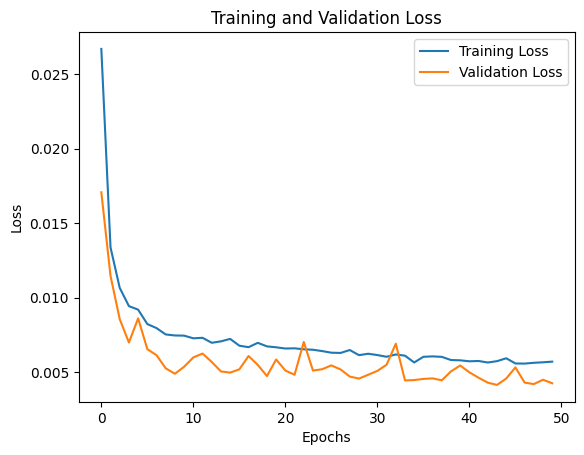

In [ ]:
# Plotting the loss and accuracy
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


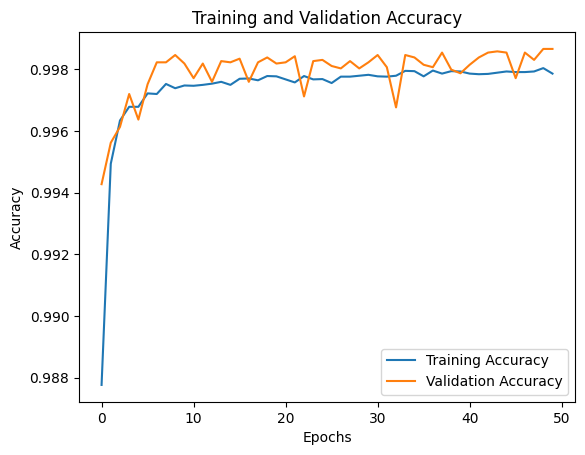

In [ ]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Drop 'timestamp' column
df = df.drop(['timestamp'], axis=1)

# Assume your DataFrame is already loaded as df
# Extracting the features (X) and the target (y)
X = df.drop(columns=['Hours_till_Failure']).values
y = df['Hours_till_Failure'].values

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling the data (important for CNNs)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Reshape y_train and y_test to 2D arrays before scaling
y_train = y_train.reshape(-1, 1)  # Reshape to a column vector
y_test = y_test.reshape(-1, 1)    # Reshape to a column vector

y_train = scaler.fit_transform(y_train)
y_test = scaler.transform(y_test)

# Reshape the input to fit the Conv1D layer: (samples, timesteps, features)
# Timesteps is 1 for this case as we are not using sequences
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

In [ ]:
y_train.shape

(101221, 1)

In [ ]:
X_train.shape

(101221, 17, 1)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Build the CNN model
model = Sequential([
    Conv1D(filters=64, kernel_size=2, activation='relu', padding="same", input_shape=(X_train.shape[1], 1)),

    Conv1D(filters=64, kernel_size=2, activation='relu', padding="same"),

    Flatten(),

    Dense(64, activation='relu'),
    Dropout(0.2),  # Dropout after the Dense layer

    Dense(1)  # Regression output layer (no activation for raw output)
])

# Compile the model with Adam optimizer and Mean Squared Error loss
#model.compile(optimizer='adam', loss='mean_squared_error')
model.compile(optimizer=Adam(learning_rate=0.001), loss='mean_squared_error')

# Print model summary
model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)                    │ (None, 17, 64)              │             192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 17, 64)              │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1088)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │          69,696 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 78,209 (305.50 KB)

 Trainable params: 78,209 (305.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Initialize early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',    # Track validation loss
    patience=10,           # Stop after 10 epochs of no improvement
    restore_best_weights=True  # Restore model weights from the epoch with the lowest validation loss
)

# Train the model
history = model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_test, y_test), callbacks=[early_stopping])

Epoch 1/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - loss: 0.5967 - val_loss: 0.5254
Epoch 2/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - loss: 0.5271 - val_loss: 0.4155
Epoch 3/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - loss: 0.4002 - val_loss: 0.3457
Epoch 4/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - loss: 0.3520 - val_loss: 0.3304
Epoch 5/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - loss: 0.3465 - val_loss: 0.3356
Epoch 6/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - loss: 0.3380 - val_loss: 0.3187
Epoch 7/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - loss: 0.3307 - val_loss: 0.3192
Epoch 8/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - loss: 0.3271 - val_loss: 0.3251
Epoch 9/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - loss: 0.3265 - val_loss: 0.3084
Epoch 10/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 0.3228 - val_loss: 0.3127
Epoch 11/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - loss: 0.3183 - val_loss: 0.3168
Epoch 12/50
1582/15

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
# Evaluate the model on the test data
test_loss = model.evaluate(X_test, y_test)
print(f'Test Loss (Mean Squared Error): {test_loss}')

# Predicting on the test set
y_pred = model.predict(X_test).flatten()  # Flattening to match true labels' shape

# Evaluate with MAE and R² Score
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"R² Score: {r2}")

791/791 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2760
Test Loss (Mean Squared Error): 0.2702174186706543
791/791 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Mean Absolute Error (MAE): 0.3763748356780316
R² Score: 0.7314475595810237


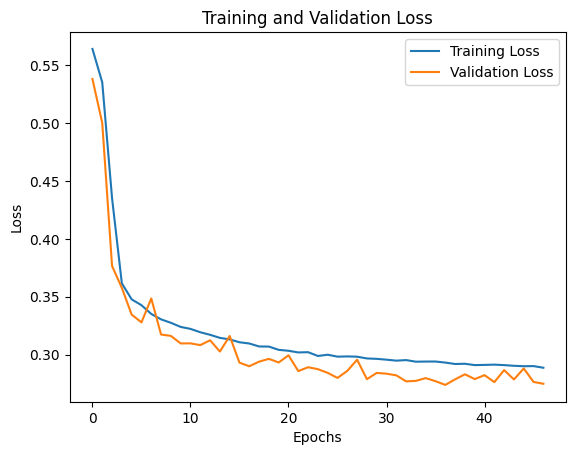

In [ ]:
import matplotlib.pyplot as plt
# Plotting the loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()